# Đom Đóm · bản nhóm thu gọn

Mình sẽ xem **toàn bộ đàn** và phương án đang lưu. Có thể sửa N/T, cả ba vùng bão, chọn l, biên, a và số đèn phát tối đa. Pin luôn 220, luôn 30 biến. Các thử riêng của Nhân nằm ở gói khác.

Chạy ô chuẩn bị, rồi ô mở bảng điều khiển. Trong giao diện, chỉnh xong nhấn **Chạy WOA**. Bật xem trực tiếp nếu muốn thấy đàn trong khi tính, hoặc dùng Play sau khi chạy. Đường xám có thể còn vi phạm; chúng không phải tất cả đều là nghiệm được công nhận.

In [1]:
# Chuẩn bị trong Colab, hoặc mở notebook từ thư mục dự án trên máy.
import os
import sys
from pathlib import Path

def find_project_root():
    # 1. Kiểm tra nếu thư mục hiện tại đã có 'src'
    if (Path.cwd() / 'src').is_dir():
        return Path.cwd()
    # 2. Tìm trong các thư mục con hoặc thư mục woa_uploaded
    for search_base in [Path.cwd(), Path.cwd() / 'woa_uploaded']:
        if search_base.exists():
            for p in search_base.rglob('src'):
                if p.is_dir():
                    if (p / 'n4_hoang_yen_du_lieu.py').exists() or (p.parent / 'kiem_tra.py').exists():
                        return p.parent
                    return p.parent
    return None

root = find_project_root()

if not root:
    # Kiểm tra xem có file zip đã tải lên sẵn trong thư mục chưa (tránh tải lại)
    zip_files = list(Path.cwd().glob('*.zip'))
    filename = None
    if zip_files:
        filename = str(zip_files[0])
        print(f'Đã tìm thấy file zip có sẵn: {filename}')
    else:
        from google.colab import files
        uploaded = files.upload()
        for name in uploaded:
            if name.lower().endswith('.zip'):
                filename = name
                break
    if not filename:
        raise ValueError('Vui lòng tải lên file ZIP của project (ví dụ: Nhom4_Whale-Optimization-Algorithm-main.zip).')
    from zipfile import ZipFile
    with ZipFile(filename) as archive:
        archive.extractall('woa_uploaded')
    root = find_project_root()

if root:
    os.chdir(str(root))
    print(f'Thư mục làm việc: {Path.cwd()}')
else:
    raise FileNotFoundError("Không tìm thấy thư mục 'src' trong project sau khi giải nén!")

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

try:
    import ipywidgets
except ModuleNotFoundError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'ipywidgets'])

try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

from src.n4_hoang_yen_du_lieu import ROOT
print('Đã sẵn sàng. Mở bảng điều khiển ở ô tiếp nhé.')


Đã sẵn sàng. Mở bảng điều khiển ở ô tiếp nhé.


In [2]:
from src.n10_bao_ngoc_demo import show_notebook_controls
show_notebook_controls()

Bảng điều khiển đã khởi tạo. Chạy lại ô để kết nối nút trong phiên Colab của bạn.


## Xem dữ liệu đã đo trước khi chạy lại

Ảnh dưới dùng seed gần trung vị của mỗi ca để minh họa map. Cột và bảng tính đủ 30 seed. Bây giờ **B là khe hẹp**, C là chắn đường; nhãn B/C đã được đổi so với bản cũ và được ghi rõ trong README.

Đây là bản đã lưu, không tự đổi theo các nút bên trên. Muốn lấy kết quả của nút mới, nhấn Chạy WOA trong bảng điều khiển.

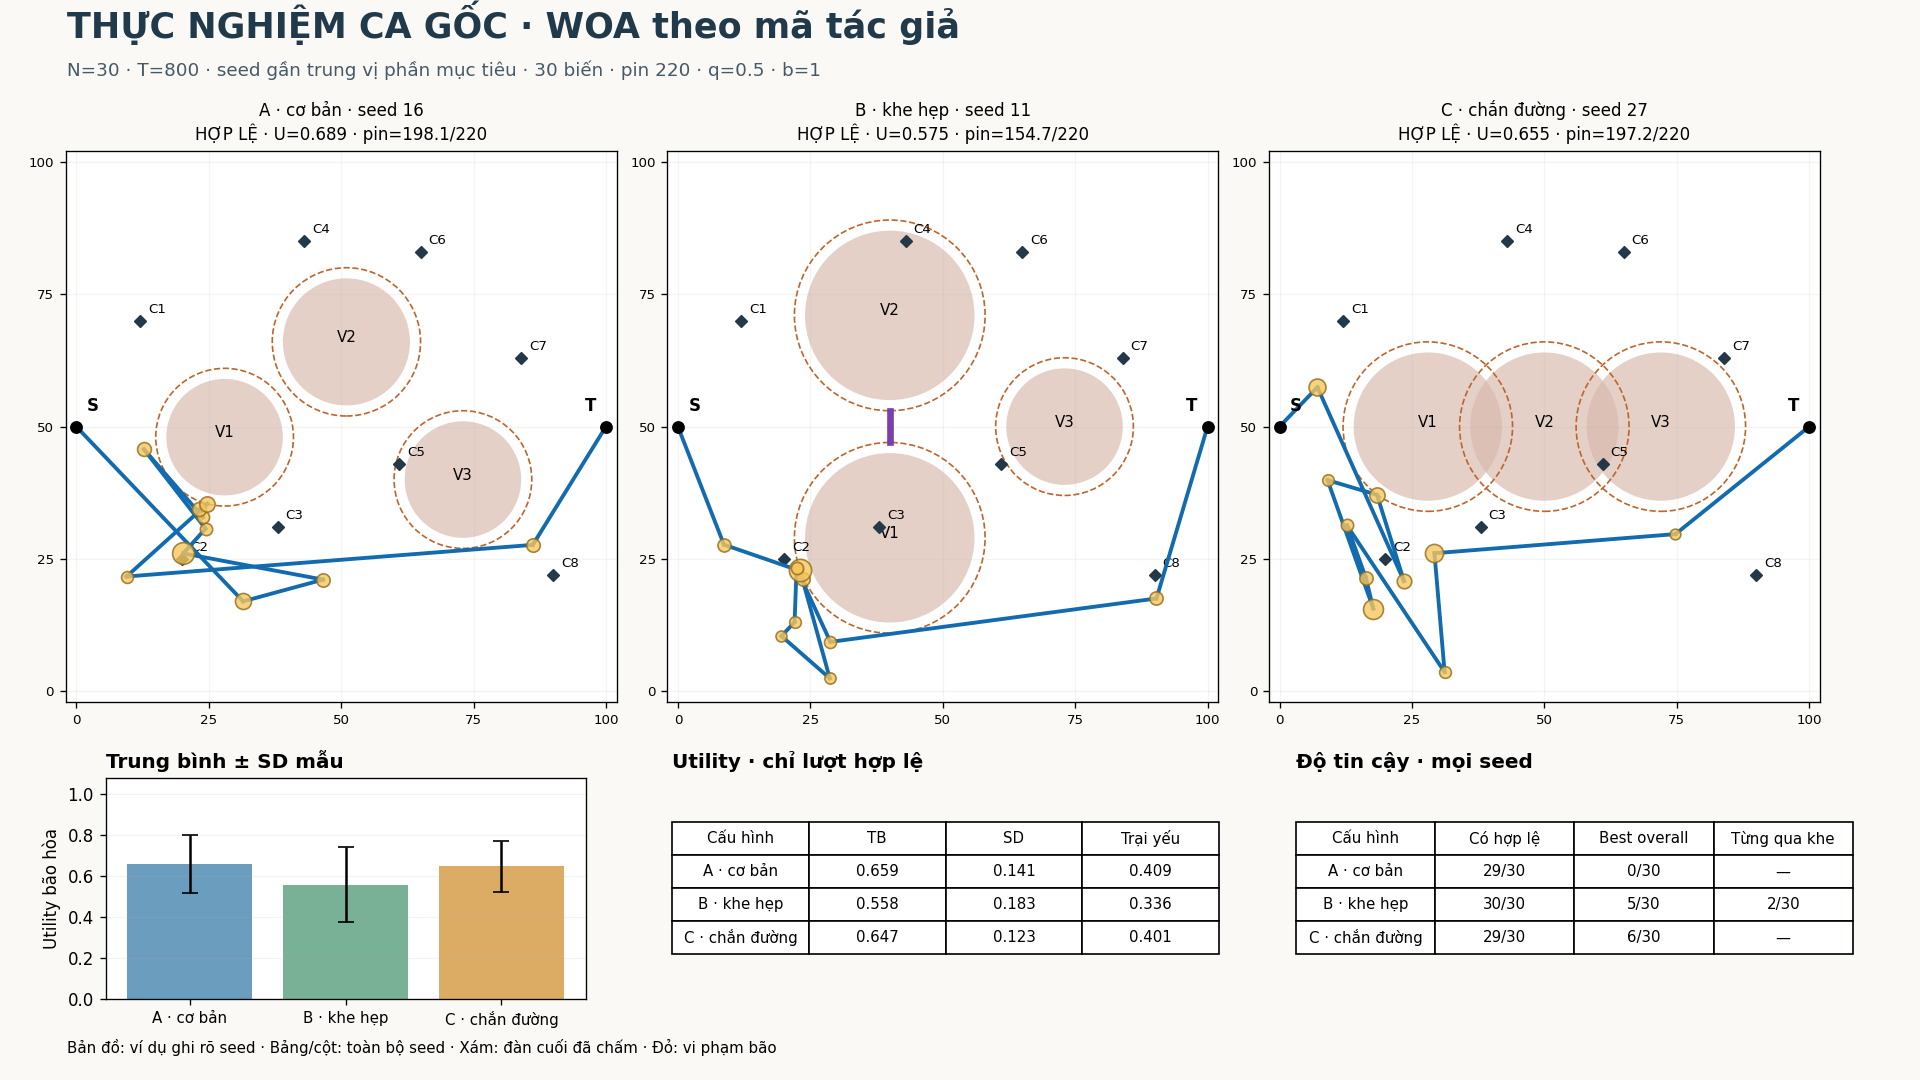

In [3]:
from IPython.display import Image, display
display(Image(filename=str(ROOT/"results/figures/00_case_goc_tong_hop.png")))

## Ảnh ngách có đủ thông tin trong một khung

Map seed7 cố định để mình nhìn ví dụ. Hai bảng và cột/râu dùng 30 seed. Râu là SD mẫu; cần đọc cùng số lần hợp lệ và ý nghĩa thước đo.

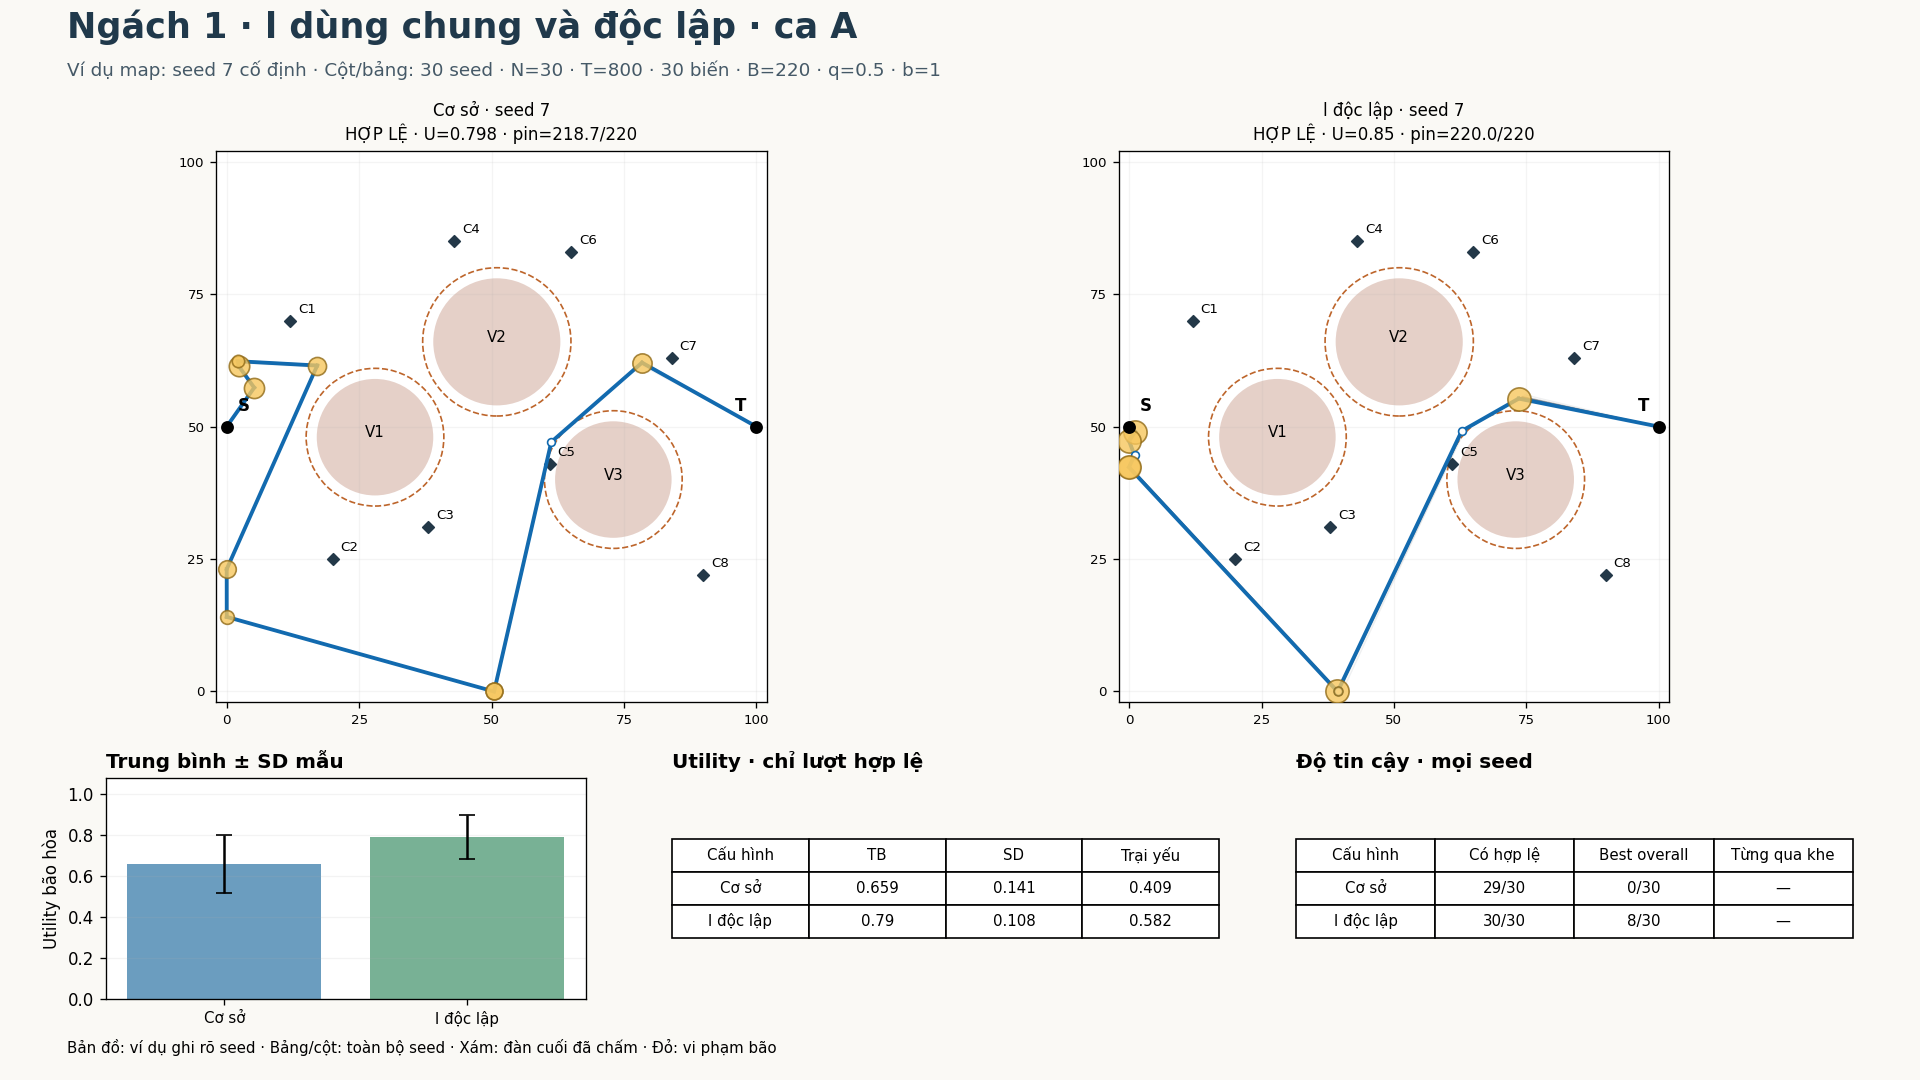

In [4]:
# Đổi tên ảnh trong danh sách để xem các ngách khác.
ten_anh="1_l_A_ONE_SHOT.png"
display(Image(filename=str(ROOT/"results/figures"/ten_anh)))

## Kiểm tra nhỏ

Đây là các kiểm tra có đáp án biết trước. Bộ đầy đủ được chấm lại bằng `python kiem_tra_ket_qua.py`. Không cần chạy lại hàng trăm lần tối ưu chỉ để mở các ảnh.

In [5]:
import kiem_tra
kiem_tra.main()

Qua kiểm tra: khe có đường hợp lệ, bão, pin, 30 biến, số đèn, a, biên, seed và benchmark.
